In [ ]:
from pathlib import Path
import mcstasscript as ms
import os, sys, shutil
from mcstasscript.interface.functions import Configurator

prefix = Path(sys.prefix)
guides = list(prefix.rglob('Guide.comp'))
mcstas_path = guides[0].parent.parent
config = Configurator()
config.set_mcstas_path(str(mcstas_path))
config.set_mcrun_path(str(Path(shutil.which('mcrun')).parent))
os.environ['MCSTAS'] = str(mcstas_path)

print('Python:', sys.executable)
print('McStas library:', mcstas_path)

# Walkthrough: pulse-shaping and bandwidth choppers



Beamline order: source → guide 1 → PSC → guide 2 → BC.

$$
t_{\mathrm{flight}}=\frac{L\lambda}{3956.0346}
$$

Use $L$ in metres, $\lambda$ in ångströms, and time in seconds. The downstream analyzer that selects final neutron energy is outside this model.

In [33]:
import mcstasscript as ms

instr = ms.McStas_instr(
    "PSCandBC",
    author="McStasScript example",
    origin="Teaching example",
)


In [34]:
pulse_length = 400.0e-6
instr.add_parameter("pulse_length", value=pulse_length,
                    comment="Proton pulse duration for the moderator model [s]")
moderator_tau = 170.0e-6
instr.add_parameter("moderator_tau", value=moderator_tau,
                    comment="Cold moderator decay time used by Source_pulsed [s]")
moderator_n = 5.0
instr.add_parameter("moderator_n", value=moderator_n,
                    comment="Cold moderator pulse-shape parameter used by Source_pulsed")
moderator_time_center = 0.5*pulse_length + moderator_tau*(moderator_n+1.0)/moderator_n
source_frequency = 50.0
instr.add_parameter("source_frequency", value=source_frequency,
                    comment="Source repetition rate [Hz]")
lambda_min = 0.5
instr.add_parameter("lambda_min", value=lambda_min,
                    comment="Minimum source wavelength [Angstrom]")
lambda_max = 10.0
instr.add_parameter("lambda_max", value=lambda_max,
                    comment="Maximum source wavelength [Angstrom]")

l1 = 2.0
instr.add_parameter("l1", value=l1,
                    comment="Length of first guide segment [m]")


Parameter named: 'l1' with value: 2.0
 [dimensionless]
 Length of first guide segment [m]

In [35]:
source = instr.add_component("source", "Source_pulsed")
source.xwidth = 0.042
source.yheight = 0.03
source.Lmin = "lambda_min"
source.Lmax = "lambda_max"
source.t_min = 0.0
source.t_max = 0.004
source.dist = 0.1
source.focus_xw = 0.04
source.focus_yh = 0.04
source.freq = "source_frequency"
source.t_pulse = "pulse_length"
source.T1 = 60.0
source.I1 = "1.75e12/source_frequency"
source.tau1 = "moderator_tau"
source.n_mod = "moderator_n"
source.I_um = "3.82e10/source_frequency"
source.tau_um = 12.0e-6
source.n_um = 5.0
source.chi_um = 0.9
source.kap_um = 2.2

guide = instr.add_component(
    "guide", "Guide", AT=[0, 0, 0.1], RELATIVE="source"
)
guide.w1 = 0.04
guide.h1 = 0.04
guide.w2 = 0.04
guide.h2 = 0.04
guide.l = "l1"
guide.m = 4.0


In [36]:

# Set the PSC order relative to the 50 Hz source. Increase this integer
# to raise the rotor frequency and shorten the gate.
psc_order = 1
instr.add_parameter("psc_order", value=psc_order,
                    comment="PSC frequency = psc_order times source frequency")
opening_PSC = 36.0
instr.add_parameter("opening_PSC", value=opening_PSC,
                    comment="PSC slit angular opening [degrees]")
chopper_distance = l1+0.12
instr.add_parameter("chopper_distance", value=chopper_distance,
                    comment="Source-to-PSC distance [m]")

psc_lambda_min = 1.0
instr.add_parameter("psc_lambda_min", value=psc_lambda_min,
                    comment="Lower wavelength edge to center on with the PSC [Angstrom]")
psc_lambda_max = 7.0
instr.add_parameter("psc_lambda_max", value=psc_lambda_max,
                    comment="Upper wavelength edge to center on with the PSC [Angstrom]")
lambda_center = 0.5 * (psc_lambda_min + psc_lambda_max)


In [37]:
instr.add_declare_var("double", "nu_PSC")
instr.add_declare_var("double", "PSC_order")
instr.add_declare_var("double", "actual_width_PSC")
instr.add_declare_var("double", "psc_source_center")
instr.add_declare_var("double", "psc_phase_lambda")
instr.add_declare_var("double", "psc_phase_time")
instr.add_declare_var("double", "psc_phase_deg")
instr.add_declare_var("double", "psc_t_start")
instr.add_declare_var("double", "psc_t_end")
instr.add_declare_var("double", "psc_target_width")
instr.add_declare_var("double", "psc_band_min")
instr.add_declare_var("double", "psc_band_max")
instr.add_declare_var("double", "psc_max_order")


Declare variable: 'psc_max_order' of type double

### Register the PSC calculations and checks


In [38]:
instr.append_initialize(
    'if (moderator_tau <= 0 || moderator_n <= 1 || source_frequency <= 0 || psc_order < 1 || fabs(psc_order-floor(psc_order+0.5)) > 1e-6 || opening_PSC <= 0 || opening_PSC >= 360 || psc_lambda_min < lambda_min || psc_lambda_max > lambda_max || psc_lambda_min <= 0 || psc_lambda_max <= psc_lambda_min) { fprintf(stderr, "PSC band must be within the source range; order, source frequency and slit opening must be valid\\n"); exit(1); }'
)
instr.append_initialize("psc_band_min = psc_lambda_min;")
instr.append_initialize("psc_band_max = psc_lambda_max;")
instr.append_initialize("psc_phase_lambda = (psc_band_min + psc_band_max)/2.0;")
instr.append_initialize("PSC_order = psc_order;")
instr.append_initialize("nu_PSC = PSC_order*source_frequency;")
instr.append_initialize("actual_width_PSC = opening_PSC/(360.0*nu_PSC);")
instr.append_initialize("psc_source_center = 0.5*pulse_length + moderator_tau*(moderator_n+1.0)/moderator_n;")
instr.append_initialize("psc_t_start = psc_source_center + chopper_distance*psc_band_min/3956.0346;")
instr.append_initialize("psc_t_end = psc_source_center + chopper_distance*psc_band_max/3956.0346;")
instr.append_initialize("psc_target_width = pulse_length + chopper_distance*(psc_band_max-psc_band_min)/3956.0346;")
instr.append_initialize("psc_max_order = floor(opening_PSC/(360.0*source_frequency*psc_target_width));")
instr.append_initialize('if (actual_width_PSC + 1e-12 < psc_target_width) { printf("WARNING: PSC gate is narrower than the nominal source-pulse plus target-band arrival span; band edges will be clipped\\n"); }')
instr.append_initialize("psc_phase_time = 0.5*(psc_t_start + psc_t_end);")
instr.append_initialize("psc_phase_deg = fmod(360.0*nu_PSC*psc_phase_time, 360.0);")
instr.append_initialize('printf("PSC order=%g, rate=%g Hz (%g rpm), gate=%g us, nominal gate requirement=%g us, largest nominal order=%g; source center=%g ms; phase=%g deg at t=%g ms\\n", PSC_order, nu_PSC, 60.0*nu_PSC, actual_width_PSC*1e6, psc_target_width*1e6, psc_max_order, 1e3*psc_source_center, psc_phase_deg, 1e3*psc_phase_time);')
instr.append_initialize(
    'if (chopper_distance < 0.1 + l1 + 0.02) { printf("PSC is too close to guide 1; increase chopper_distance or reduce l1\\n"); exit(1); }'
)


### Create the PSC component

The next cell uses the calculated `nu_PSC` and `psc_phase_deg` to set the rotation rate and angular delay.


In [39]:


psc = instr.add_component(
    "PSC", "DiskChopper",
    AT=[0, 0, "chopper_distance"], RELATIVE="source",
)
psc.radius = 0.25
psc.yheight = 0.065  
psc.theta_0 = "opening_PSC"
psc.nu = "nu_PSC"
psc.nslit = 1
psc.phase = "psc_phase_deg"
psc.abs_out = 1
psc.verbose = 1  

### Choose the BC wavelength band and guide length

The PSC timing uses `psc_lambda_min` and `psc_lambda_max` (1–7 Å). The BC uses the separate `lambda_band_min` and `lambda_band_max` parameters below (2–4 Å). `guide2_length` sets the distance between the choppers through `L_PSC_BC = guide2_length + 0.04`.

These settings must be defined before the BC initialization statements are registered and before the complete beamline is simulated.


In [40]:
lambda_band_min = 2.0
instr.add_parameter("lambda_band_min", value=lambda_band_min,
                    comment="Lower edge of selected BC wavelength band [Angstrom]")
lambda_band_max = 4.0
instr.add_parameter("lambda_band_max", value=lambda_band_max,
                    comment="Upper edge of selected BC wavelength band [Angstrom]")
lambda_bandwidth = lambda_band_max - lambda_band_min
guide2_length = 10.0
instr.add_parameter("guide2_length", value=guide2_length,
                    comment="Length of guide section between PSC and BC [m]")


Parameter named: 'guide2_length' with value: 10.0
 [dimensionless]
 Length of guide section between PSC and BC [m]

## 7. Add guide 2

In [41]:
# Guide section between the PSC and the bandwidth chopper.
# Start 20 mm after the PSC and keep the same 40 mm guide aperture.
guide2 = instr.add_component(
    "guide2", "Guide", AT=[0, 0, 0.02], RELATIVE="PSC"
)
guide2.w1 = 0.04
guide2.h1 = 0.04
guide2.w2 = 0.04
guide2.h2 = 0.04
guide2.l = "guide2_length"
guide2.m = 4.0


## 9. Measure the beam before the BC



In [42]:
# Monitor pair just after guide 2 and before the BC.
lambda_before_BC = instr.add_component(
    "lambda_before_BC", "L_monitor",
    AT=[0, 0, "guide2_length+0.005"], RELATIVE="guide2"
)
lambda_before_BC.xwidth = 0.04
lambda_before_BC.yheight = 0.04
lambda_before_BC.nL = 100
lambda_before_BC.Lmin = 0.5
lambda_before_BC.Lmax = 10.0
lambda_before_BC.restore_neutron = 1

tof_before_BC = instr.add_component(
    "tof_before_BC", "TOF_monitor",
    AT=[0, 0, "guide2_length+0.005"], RELATIVE="guide2"
)
tof_before_BC.xwidth = 0.04
tof_before_BC.yheight = 0.04
tof_before_BC.nt = 1000
tof_before_BC.tmin = 0.0
tof_before_BC.tmax = 25000.0
tof_before_BC.restore_neutron = 1


## 10. Add the bandwidth chopper

**Do:** Place the BC after guide 2. The code keeps its slit at 120° and calculates a source-synchronized rotation rate and phase for the requested band.

**Equations:** $w_{\mathrm{target,BC}}=t_{\mathrm{pulse}}+(L_s+D)\Delta\lambda/3956.0346$ and $q_{\mathrm{BC}}=\left\lfloor\theta_{\mathrm{BC}}/(360^\circ f_s w_{\mathrm{target,BC}})\right\rfloor$. Here $D$ is the PSC-to-BC distance.

### Declare the BC timing variables

Declare these variables first. The following calculation cell assigns their values before the BC component is added.

| Variable | Calculation or meaning |
| --- | --- |
| `lambda_bandwidth`, `lambda_band_center` | Difference and midpoint of the selected band edges [Å]. |
| `L_PSC_BC` | `guide2_length + 0.04`: two 20 mm gaps plus guide 2 [m]. |
| `opening_BC` | Fixed 120° slit opening. |
| `bc_target_width` | Proton-pulse duration plus wavelength-band flight-time spread over the full source-to-BC distance [s]. |
| `bc_max_order` | Floor of `opening_BC / (360 * source_frequency * bc_target_width)`. |
| `nu_BC` | `bc_max_order * source_frequency` [Hz]. |
| `gate_width_BC` | `opening_BC / (360 * nu_BC)` [s]. |
| `bc_phase_time` | `psc_source_center` plus flight time of the band-center wavelength to the BC [s]. |
| `bc_phase_deg` | `fmod(360 * nu_BC * bc_phase_time, 360)` [degrees]. |

1. Calculate the band width, center, and full travel distance.
2. Estimate the required time window and choose the largest source harmonic whose gate covers it. If no positive harmonic fits, stop with an error.
3. Calculate the actual frequency and gate duration.
4. Center the opening on the band-center arrival time and convert that delay to angular phase.


In [43]:
instr.add_declare_var("double", "L_PSC_BC")
instr.add_declare_var("double", "gate_width_BC")
instr.add_declare_var("double", "opening_BC")
instr.add_declare_var("double", "nu_BC")
instr.add_declare_var("double", "lambda_bandwidth")
instr.add_declare_var("double", "lambda_band_center")
instr.add_declare_var("double", "bc_target_width")
instr.add_declare_var("double", "bc_max_order")
instr.add_declare_var("double", "bc_phase_time")
instr.add_declare_var("double", "bc_phase_deg")


Declare variable: 'bc_phase_deg' of type double

### Register the BC calculations and checks


In [44]:
instr.append_initialize('if (lambda_band_min < lambda_min || lambda_band_max > lambda_max || lambda_band_min <= 0 || lambda_band_max <= lambda_band_min) { fprintf(stderr, "Requested BC band must lie within source wavelength limits\\n"); exit(1); }')
instr.append_initialize("lambda_bandwidth = lambda_band_max - lambda_band_min;")
instr.append_initialize("lambda_band_center = (lambda_band_min + lambda_band_max)/2.0;")
instr.append_initialize("L_PSC_BC = guide2_length + 0.04;")
instr.append_initialize("opening_BC = 120.0;")
instr.append_initialize("bc_target_width = pulse_length + (chopper_distance+L_PSC_BC)*lambda_bandwidth/3956.0346;")
instr.append_initialize("bc_max_order = floor(opening_BC/(360.0*source_frequency*bc_target_width));")
instr.append_initialize('if (bc_max_order < 1) { fprintf(stderr, "Selected wavelength band is too broad for a source-synchronized BC with a 120 degree opening\\n"); exit(1); }')
instr.append_initialize("nu_BC = bc_max_order*source_frequency;")
instr.append_initialize("gate_width_BC = opening_BC/(360.0*nu_BC);")
instr.append_initialize("bc_phase_time = psc_source_center + (chopper_distance+L_PSC_BC)*lambda_band_center/3956.0346;")
instr.append_initialize("bc_phase_deg = fmod(360.0*nu_BC*bc_phase_time, 360.0);")
instr.append_initialize('printf("BC fixed opening=%g deg; selected band=%g-%g A; required window=%g us; harmonic=%g; rate=%g Hz; actual gate=%g us; phase=%g deg at t=%g ms\\n", opening_BC, lambda_band_min, lambda_band_max, bc_target_width*1e6, bc_max_order, nu_BC, gate_width_BC*1e6, bc_phase_deg, 1e3*bc_phase_time);')
instr.append_initialize('if (opening_BC >= 360.0) { fprintf(stderr, "BC opening must be less than 360 degrees\\n"); exit(1); }')


### Create the BC component

Use the calculated frequency, opening angle, position, and phase in the component below.


In [45]:

bc = instr.add_component(
    "BC", "DiskChopper", AT=[0, 0, "L_PSC_BC"], RELATIVE="PSC"
)
bc.radius = 0.25
bc.yheight = 0.065
bc.theta_0 = "opening_BC"
bc.nu = "nu_BC"
bc.nslit = 1
bc.phase = "bc_phase_deg"
bc.abs_out = 1
bc.verbose = 1


## 11. Measure the beam after the BC

In [46]:
# Monitor pair immediately after the BC.
lambda_after_BC = instr.add_component(
    "lambda_after_BC", "L_monitor", AT=[0, 0, 0.005], RELATIVE="BC"
)
lambda_after_BC.xwidth = 0.04
lambda_after_BC.yheight = 0.04
lambda_after_BC.nL = 100
lambda_after_BC.Lmin = 0.5
lambda_after_BC.Lmax = 10.0
lambda_after_BC.restore_neutron = 1




## 12. Run the complete beamline


---- Found 1 places in McStas output with keyword 'error'. 

[mac-pro:3015883] Set MCA parameter "orte_base_help_aggregate" to 0 to see all help / error messages
*** TRACE end *** 
Detector: lambda_before_BC_I=1.08327e+10 lambda_before_BC_ERR=1.84293e+07 lambda_before_BC_N=4.26904e+06 "lambda_before_BC.dat"
Detector: tof_before_BC_I=1.08327e+10 tof_before_BC_ERR=1.84293e+07 tof_before_BC_N=4.26904e+06 "tof_before_BC.dat"
Detector: lambda_after_BC_I=6.96679e+09 lambda_after_BC_ERR=1.68933e+07 lambda_after_BC_N=1.81628e+06 "lambda_after_BC.dat"
INFO: Placing instr file copy PSCandBC.instr in dataset /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/BC/PSCandBC_1
INFO: Placing generated c-code copy PSCandBC.c in dataset /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/BC/PSCandBC_1

----------------------------------------------------------------------

INFO: Using directory: "/run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/BC/PSCandBC_1"
INFO: Regenerating c-file: PSCandBC.c
Inf

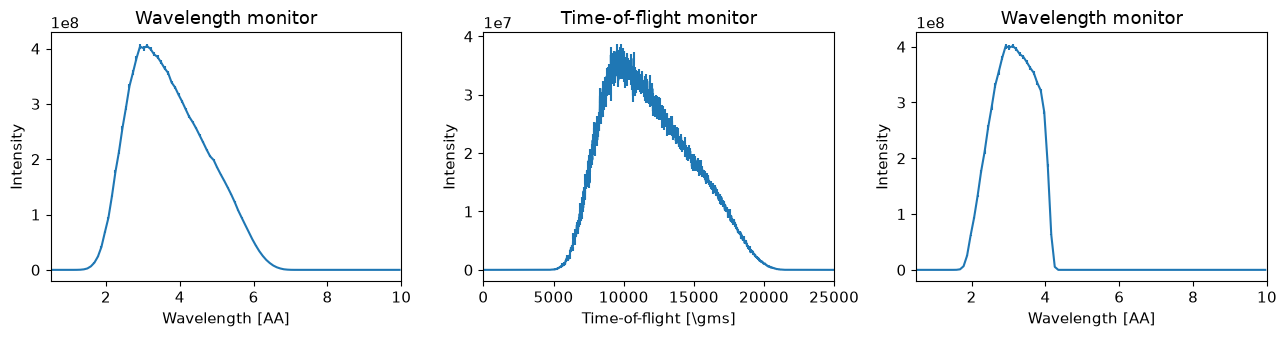

In [47]:
import os
import sys
from pathlib import Path

os.environ["MCSTAS_CC_OVERRIDE"] = "/usr/bin/gcc"
os.environ["MCSTAS_MPICC_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpicc")
os.environ["MCSTAS_MPIRUN_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpirun")
os.environ["OMPI_CC"] = "/usr/bin/gcc"
os.environ["MCSTAS_CFLAGS_OVERRIDE"] = "-O2 -march=x86-64 -mtune=generic -std=c99 -D_POSIX_SOURCE -lm"
os.environ["CFLAGS"] = ""
os.environ["LDFLAGS"] = ""

instr.settings(force_compile=True, ncount=1e9, mpi=12)
data=instr.backengine()
ms.make_sub_plot(data)

## 14. Check the wavelength band at the BC

**Do:** Compare the normalized spectra before and after the BC. The shaded region marks the requested band.



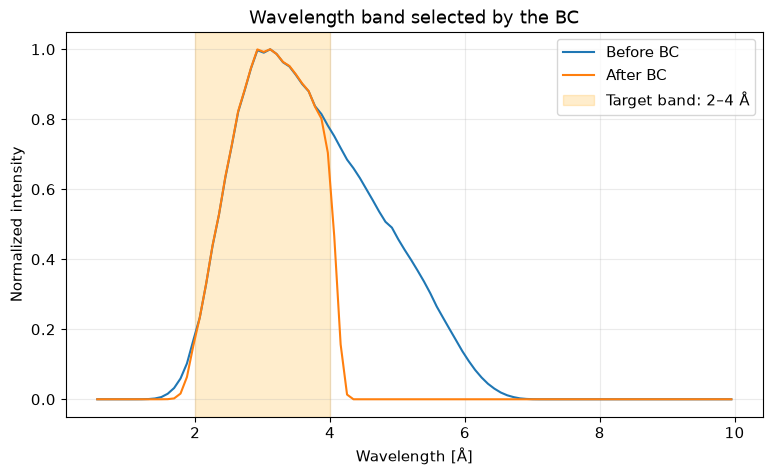

Post-BC intensity inside the target 2 Å band: 95.0%


In [48]:
# Compare wavelength spectra before and after the bandwidth chopper.
import numpy as np
import matplotlib.pyplot as plt

lambda_before = next(d for d in data if d.name == "lambda_before_BC")
lambda_after = next(d for d in data if d.name == "lambda_after_BC")
band_min = lambda_band_min
band_max = lambda_band_max

plt.figure(figsize=(9, 5))
plt.plot(lambda_before.xaxis, lambda_before.Intensity / np.max(lambda_before.Intensity), label="Before BC")
plt.plot(lambda_after.xaxis, lambda_after.Intensity / np.max(lambda_after.Intensity), label="After BC")
plt.axvspan(band_min, band_max, color="orange", alpha=0.2, label=f"Target band: {band_min:g}–{band_max:g} Å")
plt.xlabel("Wavelength [Å]")
plt.ylabel("Normalized intensity")
plt.title("Wavelength band selected by the BC")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

in_band = (lambda_after.xaxis >= band_min) & (lambda_after.xaxis <= band_max)
fraction = np.sum(lambda_after.Intensity[in_band]) / np.sum(lambda_after.Intensity)
print(f"Post-BC intensity inside the target {lambda_bandwidth:g} Å band: {100*fraction:.1f}%")
